# PCA and k-means

## Setting up

In [58]:
"""
Author      : Yi-Chieh Wu, Sriram Sankararaman
"""
import time

# numpy and scipy libraries
import numpy as np
from scipy import stats

# matplotlib libraries
import matplotlib.pyplot as plt
import collections

In [59]:
# To add your own Drive Run this cell.
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [60]:
import sys
# Change the path below to the path where your folder locates
# where you have util.py
### ========== TODO : START ========== ###
sys.path.append('/content/drive/My Drive/CS M146')
### ========== TODO : START ========== ###


In [61]:
import util
from util import *

## Point, Cluster and Set of Clusters classes

In [62]:
######################################################################
# classes
######################################################################

class Point(object) :

    def __init__(self, name, label, attrs) :
        """
        A data point.

        Attributes
        --------------------
            name  -- string, name
            label -- string, label
            attrs -- numpy arrray of shape (d, ) where d is the number of features
        """

        self.name = name
        self.label = label
        self.attrs = attrs


    #============================================================
    # utilities
    #============================================================

    def distance(self, other) :
        """
        Return Euclidean distance of this point with other point.

        Parameters
        --------------------
            other -- Point, point to which we are measuring distance

        Returns
        --------------------
            dist  -- float, Euclidean distance
        """
        # Euclidean distance metric
        return np.linalg.norm(self.attrs-other.attrs)


    def __str__(self) :
        """
        Return string representation.
        """
        return "%s : (%s, %s)" % (self.name, str(self.attrs), self.label)

In [63]:
class Cluster(object) :

    def __init__(self, points) :
        """
        A cluster (set of points).

        Attributes
        --------------------
            points -- list of Points, cluster elements
        """
        self.points = points


    def __str__(self) :
        """
        Return string representation.
        """
        s = ""
        for point in self.points :
            s += str(point)
        return s

    #============================================================
    # utilities
    #============================================================

    def purity(self) :
        """
        Compute cluster purity.

        Returns
        --------------------
            n           -- int, number of points in this cluster
            num_correct -- int, number of points in this cluster
                                with label equal to most common label in cluster
        """
        labels = []
        for p in self.points:
            labels.append(p.label)

        cluster_label, count = stats.mode(labels)
        return len(labels), np.float64(count)


    def centroid(self) :
        """
        Compute centroid of this cluster.

        Returns
        --------------------
            centroid -- Point, centroid of cluster
        """

        ### ========== TODO : START ========== ###
        # part 2b: implement
        # set the centroid label to any value (e.g. the most common label in this cluster)
        labels = []
        for p in self.points:
          labels.append(p.label)
        centroid_label = np.argmax(np.bincount(labels))
        centroid_attrs = np.mean([p.attrs for p in self.points],axis=0)
        centroid = Point("centroid", centroid_label, centroid_attrs)

        return centroid
        ### ========== TODO : END ========== ###



    def medoid(self) :
        """
        Compute medoid of this cluster, that is, the point in this cluster
        that is closest to all other points in this cluster.

        Returns
        --------------------
            medoid -- Point, medoid of this cluster
        """

        ### ========== TODO : START ========== ###
        # part 2b: implement

        min_distance = float('inf')

        for p in self.points:
          distance = sum(p.distance(other) for other in self.points)
          if distance < min_distance:
            min_distance = distance
            medoid = p

        return medoid
        ### ========== TODO : END ========== ###


    def equivalent(self, other) :
        """
        Determine whether this cluster is equivalent to other cluster.
        Two clusters are equivalent if they contain the same set of points
        (not the same actual Point objects but the same geometric locations).

        Parameters
        --------------------
            other -- Cluster, cluster to which we are comparing this cluster

        Returns
        --------------------
            flag  -- bool, True if both clusters are equivalent or False otherwise
        """

        if len(self.points) != len(other.points) :
            return False

        matched = []
        for point1 in self.points :
            for point2 in other.points :
                if point1.distance(point2) == 0 and point2 not in matched :
                    matched.append(point2)
        return len(matched) == len(self.points)

In [64]:
class ClusterSet(object):

    def __init__(self) :
        """
        A cluster set (set of clusters).

        Parameters
        --------------------
            members -- list of Clusters, clusters that make up this set
        """
        self.members = []


    #============================================================
    # utilities
    #============================================================

    def centroids(self) :
        """
        Return centroids of each cluster in this cluster set.

        Returns
        --------------------
            centroids -- list of Points, centroids of each cluster in this cluster set
        """

        ### ========== TODO : START ========== ###
        # part 2b: implement
        centroids = []
        for cluster in self.members:
          centroids.append(cluster.centroid())
        return centroids
        ### ========== TODO : END ========== ###


    def medoids(self) :
        """
        Return medoids of each cluster in this cluster set.

        Returns
        --------------------
            medoids -- list of Points, medoids of each cluster in this cluster set
        """

        ### ========== TODO : START ========== ###
        # part 2b: implement
        medoids = []
        for cluster in self.members:
          medoids.append(cluster.medoid())
        return medoids
        ### ========== TODO : END ========== ###


    def score(self) :
        """
        Compute average purity across clusters in this cluster set.

        Returns
        --------------------
            score -- float, average purity
        """

        total_correct = 0
        total = 0
        for c in self.members :
            n, n_correct = c.purity()
            total += n
            total_correct += n_correct
        return total_correct / float(total)


    def equivalent(self, other) :
        """
        Determine whether this cluster set is equivalent to other cluster set.
        Two cluster sets are equivalent if they contain the same set of clusters
        (as computed by Cluster.equivalent(...)).

        Parameters
        --------------------
            other -- ClusterSet, cluster set to which we are comparing this cluster set

        Returns
        --------------------
            flag  -- bool, True if both cluster sets are equivalent or False otherwise
        """

        if len(self.members) != len(other.members):
            return False

        matched = []
        for cluster1 in self.members :
            for cluster2 in other.members :
                if cluster1.equivalent(cluster2) and cluster2 not in matched:
                    matched.append(cluster2)
        return len(matched) == len(self.members)


    #============================================================
    # manipulation
    #============================================================

    def add(self, cluster):
        """
        Add cluster to this cluster set (only if it does not already exist).

        If the cluster is already in this cluster set, raise a ValueError.

        Parameters
        --------------------
            cluster -- Cluster, cluster to add
        """

        if cluster in self.members :
            raise ValueError

        self.members.append(cluster)

## k-means and k-medoids algorithms

In [65]:
######################################################################
# k-means and k-medoids
######################################################################

def random_init(points, k) :
    """
    Randomly select k unique elements from points to be initial cluster centers.

    Parameters
    --------------------
        points         -- list of Points, dataset
        k              -- int, number of clusters

    Returns
    --------------------
        initial_points -- list of k Points, initial cluster centers
    """
    ### ========== TODO : START ========== ###
    # part 2c: implement (hint: use np.random.choice)
    initial_points = np.random.choice(points, size=k, replace=False)
    return initial_points
    ### ========== TODO : END ========== ###


def cheat_init(points) :
    """
    Initialize clusters by cheating!

    Details
    - Let k be number of unique labels in dataset.
    - Group points into k clusters based on label (i.e. class) information.
    - Return medoid of each cluster as initial centers.

    Parameters
    --------------------
        points         -- list of Points, dataset

    Returns
    --------------------
        initial_points -- list of k Points, initial cluster centers
    """
    ### ========== TODO : START ========== ###
    # part 2f: implement

    clusters = {}
    for p in points:
      if p.label not in clusters:
        clusters[p.label] = []
      clusters[p.label].append(p)

    initial_points = []
    for value in clusters.values():
      medoid = Cluster(value).medoid()
      initial_points.append(medoid)

    return initial_points
    ### ========== TODO : END ========== ###

def kAverages(points, k, average, init='random', plot=False) :
    """
    Cluster points into k clusters using variations of k-means algorithm.

    Parameters
    --------------------
        points  -- list of Points, dataset
        k       -- int, number of clusters
        average -- method of ClusterSet
                   determines how to calculate average of points in cluster
                   allowable: ClusterSet.centroids, ClusterSet.medoids
        init    -- string, method of initialization
                   allowable:
                       'cheat'  -- use cheat_init to initialize clusters
                       'random' -- use random_init to initialize clusters
        plot    -- bool, True to plot clusters with corresponding averages
                         for each iteration of algorithm

    Returns
    --------------------
        k_clusters -- ClusterSet, k clusters
    """
    ### ========== TODO : START ========== ###
    # part 2c,2d: implement
    if init == "random":
      centers = random_init(points,k)
    else:
      centers = cheat_init(points)

    converged = False
    i=1

    k_clusters = ClusterSet()
    while not converged:
      new_assignments = {}
      for c in centers:
        new_assignments[c] = []

      for p in points:
        closest_center = min(centers, key=lambda c: p.distance(c))
        new_assignments[closest_center].append(p)

      old_k_clusters = k_clusters
      k_clusters = ClusterSet()

      for assignment in new_assignments.values():
        k_clusters.add(Cluster(assignment))
      centers = average(k_clusters)
      print(f"Iteration {i}")
      converged = old_k_clusters.equivalent(k_clusters)

      if plot:
        plot_clusters(k_clusters,f"Iteration {i}", average)
      i+=1
    return k_clusters
    ### ========== TODO : END ========== ###


def kMeans(points, k, init='random', plot=False) :
    """
    Cluster points into k clusters using variations of k-means algorithm.

    Parameters
    --------------------
        points  -- list of Points, dataset
        k       -- int, number of clusters
        init    -- string, method of initialization
                   allowable:
                       'cheat'  -- use cheat_init to initialize clusters
                       'random' -- use random_init to initialize clusters
        plot    -- bool, True to plot clusters with corresponding averages
                         for each iteration of algorithm

    Returns
    --------------------
        k_clusters -- ClusterSet, k clusters
    """

    ### ========== TODO : START ========== ###
    # part 2c: implement
    # Hints:
    #   (1) On each iteration, keep track of the new cluster assignments
    #       in a separate data structure. Then use these assignments to create
    #       a new ClusterSet object and update the centroids.
    #   (2) Repeat until the clustering no longer changes.
    #   (3) To plot, use plot_clusters(...).

    if init == "random":
      centers = random_init(points,k)
    else:
      centers = cheat_init(points)

    converged = False
    i=1

    k_clusters = ClusterSet()
    while not converged:
      new_assignments = {}
      for c in centers:
        new_assignments[c] = []

      for p in points:
        closest_center = min(centers, key=lambda c: p.distance(c))
        new_assignments[closest_center].append(p)

      old_k_clusters = k_clusters
      k_clusters = ClusterSet()

      for assignment in new_assignments.values():
        k_clusters.add(Cluster(assignment))
      centers = k_clusters.centroids()
      print(f"Iteration {i}")
      converged = old_k_clusters.equivalent(k_clusters)

      if plot:
        plot_clusters(k_clusters,f"Iteration {i}", ClusterSet.centroids)
      i+=1
    return k_clusters
    ### ========== TODO : END ========== ###


def kMedoids(points, k, init='random', plot=False) :
    """
    Cluster points in k clusters using k-medoids clustering.
    See kMeans(...).
    """
    ### ========== TODO : START ========== ###
    # part 2e: implement
    return kAverages(points,k,ClusterSet.medoids,init,plot)
    ### ========== TODO : END ========== ###


## Utilities

In [66]:
######################################################################
# helper functions
######################################################################

def build_face_image_points(X, y) :
    """
    Translate images to (labeled) points.

    Parameters
    --------------------
        X     -- numpy array of shape (n,d), features (each row is one image)
        y     -- numpy array of shape (n,), targets

    Returns
    --------------------
        point -- list of Points, dataset (one point for each image)
    """

    n,d = X.shape

    images = collections.defaultdict(list) # key = class, val = list of images with this class
    for i in range(n) :
        images[y[i]].append(X[i,:])

    points = []
    for face in images :
        count = 0
        for im in images[face] :
            points.append(Point(str(face) + '_' + str(count), face, im))
            count += 1

    return points


def plot_clusters(clusters, title, average) :
    """
    Plot clusters along with average points of each cluster.

    Parameters
    --------------------
        clusters -- ClusterSet, clusters to plot
        title    -- string, plot title
        average  -- method of ClusterSet
                    determines how to calculate average of points in cluster
                    allowable: ClusterSet.centroids, ClusterSet.medoids
    """

    plt.figure()
    np.random.seed(20)
    label = 0
    colors = {}
    centroids = average(clusters)
    for c in centroids :
        coord = c.attrs
        plt.plot(coord[0],coord[1], 'ok', markersize=12)
    for cluster in clusters.members :
        label += 1
        colors[label] = np.random.rand(3,)
        for point in cluster.points :
            coord = point.attrs
            plt.plot(coord[0], coord[1], 'o', color=colors[label])
    plt.title(title)
    plt.show()


def generate_points_2d(N, seed=1234) :
    """
    Generate toy dataset of 3 clusters each with N points.

    Parameters
    --------------------
        N      -- int, number of points to generate per cluster
        seed   -- random seed

    Returns
    --------------------
        points -- list of Points, dataset
    """
    np.random.seed(seed)

    mu = [[0,0.5], [1,1], [2,0.5]]
    sigma = [[0.1,0.1], [0.25,0.25], [0.15,0.15]]

    label = 0
    points = []
    for m,s in zip(mu, sigma) :
        label += 1
        for i in range(N) :
            x = random_sample_2d(m, s)
            points.append(Point(str(label)+'_'+str(i), label, x))

    return points

## Main function

Total dataset size:
	num_samples: 1867
	num_features: 1850
	num_classes: 19
Iteration 1
Iteration 2
Iteration 3
0.9875


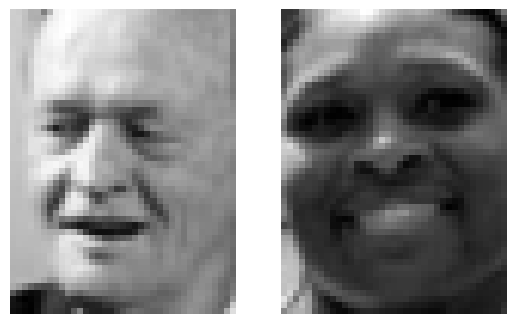

Iteration 1
Iteration 2
Iteration 3
Iteration 4
Iteration 5
Iteration 6
0.8125


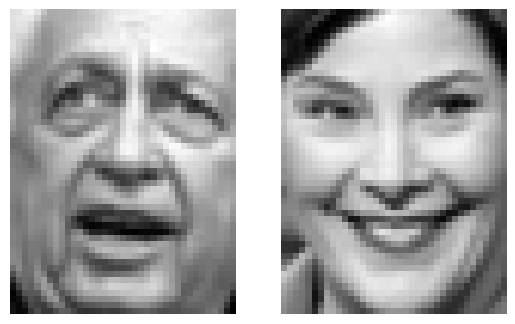

In [69]:

from os import waitstatus_to_exitcode
######################################################################
# main
######################################################################

def main() :
    ### ========== TODO : START ========== ###
    # part 1: explore LFW data set
    # part a

    # Use get_lfw_data(...) to get the LFW dataset with labels,
    X,y = get_lfw_data()
    # show_image(X[1])
    # show_image(X[15])
    # show_image(np.mean(X,axis=0))

    # part b
    ## how the top twelve eigenfaces using PCA
    U,mu = util.PCA(X)
    # plot_gallery([vec_to_image(U[:,i]) for i in range(12)])

    # part c
    ## compare the original image with the reconstructions
    # for l in [1,10,50,100,500,1288]:
    #   Z,Ul = apply_PCA_from_Eig(X,U,l,mu)
    #   X_rec = reconstruct_from_PCA(Z,Ul,mu)
    #   plot_gallery(X_rec[:12])

    ### ========== TODO : END ========== ###



    ### ========== TODO : START ========== ###
    # part 2d-2f: cluster toy dataset
    # points = generate_points_2d(20)
    # kMeans(points,3,init='random',plot=True)
    # kMedoids(points,3,init='random',plot=True)

    # kMeans(points,3,init='cheat',plot=True)
    # kMedoids(points,3,init='cheat',plot=True)
    # ### ========== TODO : END ========== ###



    ### ========== TODO : START ========== ###
    # part 3a: cluster faces
    np.random.seed(1234) ## don't change the seed !!
    # X1, y1 = util.limit_pics(X, y, [4, 6, 13, 16], 40)
    # points = build_face_image_points(X1,y1)

    # mean_scores = []
    # med_scores = []
    # for i in range (1,11):
    #   mean_clusters = kMeans(points,4,init='random',plot=False)
    #   med_clusters = kMedoids(points,4,init='random',plot=False)
    #   mean_scores.append(mean_clusters.score())
    #   med_scores.append(med_clusters.score())
    #   i+=1

    # print(f"Mean Scores: {mean_scores}")
    # print(f"Medoid Scores: {med_scores}")
    # print(f"Mean Average: {np.mean(mean_scores)}, Medoid Average: {np.mean(med_scores)}")
    # print(f"Mean Min: {np.min(mean_scores)}, Medoid Min: {np.min(med_scores)}")
    # print(f"Mean Max: {np.max(mean_scores)}, Medoid Max: {np.max(med_scores)}")


    # part 3b: explore effect of lower-dimensional representations on clustering performance
    # np.random.seed(1234) ## don't change the seed !!
    # X2, y2 = util.limit_pics(X, y, [4, 13], 40)
    # scores1 = []
    # scores2 = []
    # for l in range(1,42,2):
    #   Z, Ul = apply_PCA_from_Eig(X2,U,l,mu)
    #   points = build_face_image_points(Z,y2)
    #   X_rec = reconstruct_from_PCA(Z,Ul,mu)
    #   clusters1 = kMeans(points,2,init='cheat',plot=False)
    #   clusters2 = kMedoids(points,2,init='cheat',plot=False)
    #   scores1.append(clusters1.score())
    #   scores2.append(clusters2.score())

    # l = [i for i in range(1,42,2)]
    # plt.plot(l,scores1,label='kMeans')
    # plt.plot(l,scores2,label='kMedoids')
    # plt.xlabel('Number of Principal Components')
    # plt.ylabel('Scores')
    # plt.legend()
    # plt.show()

  # 0 and 16, 3 and 6, 3 and 16, 4 and 16, 4 and 6, 16 and 17
 # 9,16 0.9875

    # part 3c: determine ``most discriminative'' and ``least discriminative'' pairs of images
    np.random.seed(1234) ## don't change the seed !!

    X3, y3 = util.limit_pics(X,y,[9,16],40)
    points = build_face_image_points(X3,y3)
    clusters = kMeans(points,2,init='random',plot=False)
    print(clusters.score())
    plot_representative_images(X,y,labels=[9,16])

    X4, y4 = util.limit_pics(X,y, [13,0], 40)
    points = build_face_image_points(X4,y4)
    clusters = kMeans(points,2,init='random',plot=False)
    print(clusters.score())
    plot_representative_images(X,y,labels=[0,13])

    ### ========== TODO : END ========== ###


if __name__ == "__main__" :
    main()

a) This average face looks very generic and it is hard to recognize compared to the few individual images we plotted earlier. We see a blurring of key features that would help identify a face, such as bone structure, eye shape, mouth shape, etc. Instead, there is a vague figure of these parts of the face in their places.

b) I think these are the top eigenfaces since they show large variations across the general features in the dataset. For example, we see the lighting and shadows go from very bright to very dark. It makes sense that the top eigenfaces represent the variance overall across pictures.

c) The higher the l, or the number of principal components being used is, the more clear the image appears. I can clearly recognize who some of the images are, and this is likely due to more components being included. When l = 1, almost every image looks the same, because that principal component probably has less variance?

2) a) We would minimize the total distance between each datapoint and the nearest cluster center by having each datapoint be its own cluster. This is not ideal since it would likely lead to overfitting rather than learning generalizable patterns in the data. The minimum possible value of J is 0. In this case, c = {1,...n}, mu = x^j for all j in {1,...n}, and k = n, the number of datapoints since we have one cluster for each point.

6/19 done